In [1]:
from google.colab import auth

auth.authenticate_user()

In [3]:
from google.cloud import bigquery

from config import PROJECT_ID, TABLES

In [4]:
PROJECT = "pi4-vacinacao-poa"

client = bigquery.Client(project=PROJECT)


In [5]:

# 3. KPIs
# -------------------------

df_kpis = client.query("""
    SELECT *
    FROM `pi4-vacinacao-poa.pni_gold.tb_visao_geral_kpis`
""").to_dataframe()

# -------------------------
# 4. Séries temporais
# -------------------------

df_series = client.query("""
    SELECT *
    FROM `pi4-vacinacao-poa.pni_gold.tb_series_temporais_doses`
""").to_dataframe()

# -------------------------
# 5. Dados espaciais
# -------------------------

df_cluster = client.query("""
    SELECT *
    FROM `pi4-vacinacao-poa.pni_gold.tb_clustering_espacial_cep`
""").to_dataframe()

In [6]:
from feature_engineering import (
    create_cluster_features,
    get_cluster_matrix,
    CLUSTER_FEATURES
)

df_cluster_features, X_cluster = (
    get_cluster_matrix(df_cluster)
)

X_cluster.head()

,media_idade,pct_criancas,pct_adultos,pct_idosos,pct_feminino,pct_masculino,pct_influenza,pct_covid,doses_por_paciente,log_total_doses
0,0.0,1.0,0.0,0.0,1.0,0.0,0.2,0.0,10.0,2.397895
1,0.0,1.0,0.0,0.0,1.0,0.0,0.2,0.0,10.0,2.397895
2,3.7,0.923077,0.076923,0.0,0.923077,0.076923,0.384615,0.0,6.5,2.639057
3,5.7,0.8,0.2,0.0,0.9,0.1,0.3,0.0,3.333333,2.397895
4,7.1,0.857143,0.142857,0.0,0.142857,0.857143,0.142857,0.0,4.666667,2.70805


In [7]:
X_cluster.describe().T

,count,mean,std,min,25%,50%,75%,max
media_idade,1102.0,36.715064,9.554274,0.0,31.9,37.0,42.575,69.0
pct_criancas,1102.0,0.152755,0.166003,0.0,0.016171,0.11378,0.214286,1.0
pct_adultos,1102.0,0.586004,0.196616,0.0,0.421053,0.615385,0.730051,1.0
pct_idosos,1102.0,0.193586,0.145522,0.0,0.081081,0.166667,0.281851,0.9
pct_feminino,1102.0,0.558569,0.140331,0.0,0.48666,0.570063,0.624691,1.0
pct_masculino,1102.0,0.441407,0.140333,0.0,0.375309,0.429937,0.51334,1.0
pct_influenza,1102.0,0.64152,0.166351,0.0,0.562644,0.653699,0.742857,1.0
pct_covid,1102.0,0.058686,0.052456,0.0,0.015748,0.051222,0.088159,0.3
doses_por_paciente,1102.0,1.381054,0.512611,1.0,1.181818,1.283312,1.454545,10.0
log_total_doses,1102.0,4.361313,1.845234,2.397895,2.890372,3.795426,5.302058,12.110052


In [8]:
X_cluster.corr().round(2)

,media_idade,pct_criancas,pct_adultos,pct_idosos,pct_feminino,pct_masculino,pct_influenza,pct_covid,doses_por_paciente,log_total_doses
media_idade,1.00,-0.77,0.16,0.75,0.11,-0.11,0.38,0.38,-0.37,0.05
pct_criancas,-0.77,1.00,-0.62,-0.27,0.02,-0.03,-0.55,-0.14,0.51,0.12
pct_adultos,0.16,-0.62,1.00,-0.49,-0.17,0.17,0.51,-0.27,-0.39,-0.25
pct_idosos,0.75,-0.27,-0.49,1.00,0.22,-0.22,-0.02,0.50,-0.07,0.17
pct_feminino,0.11,0.02,-0.17,0.22,1.00,-1.00,-0.11,0.18,0.16,0.01
pct_masculino,-0.11,-0.03,0.17,-0.22,-1.00,1.00,0.11,-0.18,-0.16,-0.01
pct_influenza,0.38,-0.55,0.51,-0.02,-0.11,0.11,1.00,-0.20,-0.53,-0.01
pct_covid,0.38,-0.14,-0.27,0.50,0.18,-0.18,-0.20,1.00,0.05,0.15
doses_por_paciente,-0.37,0.51,-0.39,-0.07,0.16,-0.16,-0.53,0.05,1.00,-0.03
log_total_doses,0.05,0.12,-0.25,0.17,0.01,-0.01,-0.01,0.15,-0.03,1.00


Engenharia de atributos para o modelo de clustering

A análise exploratória inicial mostrou que as variáveis utilizadas para caracterizar os CEPs apresentavam forte assimetria e elevada correlação entre si. Variáveis como total_doses, total_pacientes_unicos, doses por faixa etária, sexo e imunobiológico apresentaram correlações próximas de 1,00. Esse comportamento ocorre porque todas essas variáveis são expressas em valores absolutos: um CEP que registra um volume elevado de vacinação tende naturalmente a apresentar valores maiores em praticamente todas as demais contagens. Dessa forma, caso essas variáveis fossem utilizadas diretamente no K-Means, o algoritmo poderia formar grupos principalmente com base no tamanho ou volume de vacinação de cada CEP, em vez de identificar diferenças no perfil de vacinação das regiões.

Para reduzir esse efeito, foi realizada uma etapa de engenharia de atributos, transformando parte das contagens absolutas em indicadores relativos. Foram criadas as variáveis pct_criancas, pct_adultos e pct_idosos, representando a participação de cada grupo etário sobre o total de doses do CEP; pct_feminino e pct_masculino, representando a composição das aplicações segundo o sexo; e pct_influenza e pct_covid, representando a participação desses imunobiológicos no volume total de doses. Também foi criado o indicador doses_por_paciente, calculado pela razão entre o número de doses aplicadas e o número de pacientes únicos, permitindo representar a intensidade de aplicações independentemente do tamanho absoluto do CEP.

A informação referente ao volume total de vacinação não foi completamente descartada, pois ela ainda pode ser relevante para diferenciar os territórios. Entretanto, como a distribuição de total_doses apresentou forte assimetria e alguns CEPs com volumes muito superiores aos demais, foi aplicada a transformação logarítmica log(1 + total_doses), gerando a variável log_total_doses. Essa transformação reduz a influência dos valores extremos e comprime a escala da variável, preservando ao mesmo tempo a informação relativa ao porte da vacinação de cada CEP.

Após as transformações, a análise descritiva mostrou que, em média, aproximadamente 15,3% das doses estão associadas à faixa de 0 a 5 anos, 58,6% aos adultos entre 18 e 59 anos e 19,4% aos idosos com 60 anos ou mais. A idade média observada entre os CEPs foi de aproximadamente 36,7 anos. Em relação ao sexo, a participação média foi de aproximadamente 55,9% para o sexo feminino e 44,1% para o masculino. Entre os imunobiológicos utilizados como indicadores específicos, a influenza apresentou participação média de aproximadamente 64,2%, enquanto a Covid representou cerca de 5,9% das doses. O indicador doses_por_paciente apresentou média de aproximadamente 1,38 dose por paciente e mediana de 1,28, embora tenham sido observados alguns valores superiores que deverão ser acompanhados durante a modelagem.

A nova matriz de correlação mostrou uma mudança importante em relação às variáveis originais. As correlações praticamente perfeitas observadas anteriormente deixaram de predominar e passaram a aparecer relações mais relacionadas à composição dos perfis. A variável media_idade, por exemplo, apresentou correlação de -0,77 com pct_criancas e de 0,75 com pct_idosos, indicando que CEPs com maior participação de crianças tendem a apresentar menor idade média, enquanto aqueles com maior proporção de idosos apresentam idade média mais elevada. Também foi observada correlação negativa de -0,62 entre pct_criancas e pct_adultos, além de relação positiva de aproximadamente 0,50 entre pct_idosos e pct_covid. Essas relações indicam que, após a transformação, as variáveis passaram a capturar diferenças de composição dos CEPs, e não apenas diferenças no volume absoluto de vacinação.

Um ponto específico identificado foi a correlação de -1,00 entre pct_feminino e pct_masculino. Isso ocorre porque as duas variáveis são complementares: à medida que aumenta a participação de um dos grupos, a participação do outro diminui proporcionalmente. Dessa forma, manter ambas no K-Means atribuiria peso duplicado à dimensão relacionada ao sexo. Por esse motivo, uma delas deverá ser removida antes do treinamento, mantendo apenas uma variável para representar essa característica.

De maneira geral, a etapa de engenharia de atributos permitiu construir uma representação mais adequada dos CEPs para o clustering. Enquanto as variáveis originais estavam fortemente associadas ao volume de vacinação, as novas features permitem diferenciar os territórios de acordo com sua composição etária, perfil de aplicação por sexo, participação de imunobiológicos, intensidade de vacinação e porte relativo. Com essa preparação, espera-se que os clusters obtidos pelo K-Means representem perfis distintos de vacinação e sejam mais úteis para a interpretação epidemiológica e para o apoio ao planejamento da Vigilância Epidemiológica.

In [24]:
import importlib
import feature_engineering

importlib.reload(feature_engineering)

from feature_engineering import (
    get_cluster_matrix,
    CLUSTER_FEATURES
)

print(CLUSTER_FEATURES)

['media_idade', 'pct_criancas', 'pct_adultos', 'pct_idosos', 'pct_feminino', 'pct_influenza', 'pct_covid', 'doses_por_paciente', 'log_total_doses']


In [25]:
df_cluster_features, X_cluster = get_cluster_matrix(df_cluster)

print(X_cluster.columns.tolist())
print("Quantidade de features:", X_cluster.shape[1])

['media_idade', 'pct_criancas', 'pct_adultos', 'pct_idosos', 'pct_feminino', 'pct_influenza', 'pct_covid', 'doses_por_paciente', 'log_total_doses']
Quantidade de features: 9


In [26]:
X_scaled, scaler = scale_features(X_cluster)

avaliacao_k = evaluate_kmeans(
    X_scaled,
    k_min=2,
    k_max=10
)

avaliacao_k

,k,inertia,silhouette
0,2,7948.838864,0.278435
1,3,6291.572027,0.261601
2,4,5624.313378,0.254300
3,5,4968.625852,0.260202
4,6,4554.963851,0.193744
5,7,4228.192861,0.186781
6,8,3946.212862,0.188338
7,9,3728.121092,0.181377
8,10,3545.505571,0.189837


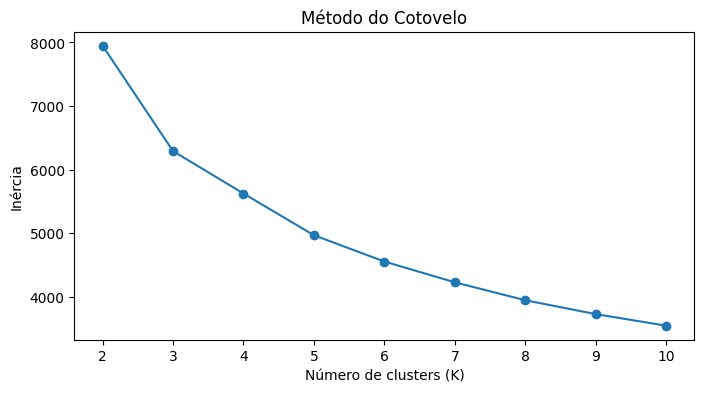

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))

plt.plot(
    avaliacao_k["k"],
    avaliacao_k["inertia"],
    marker="o"
)

plt.xlabel("Número de clusters (K)")
plt.ylabel("Inércia")
plt.title("Método do Cotovelo")

plt.show()

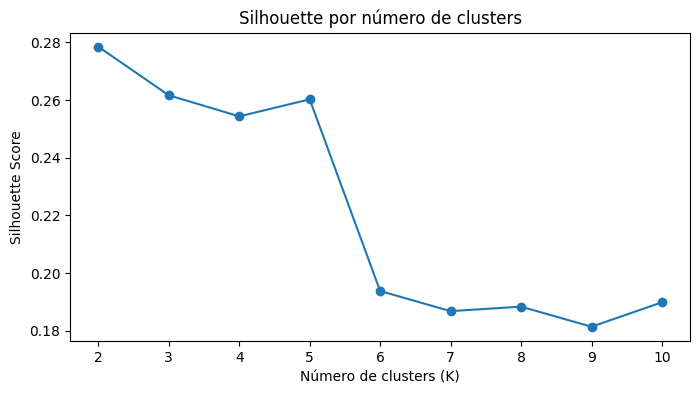

In [29]:
plt.figure(figsize=(8, 4))

plt.plot(
    avaliacao_k["k"],
    avaliacao_k["silhouette"],
    marker="o"
)

plt.xlabel("Número de clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette por número de clusters")

plt.show()

Após a remoção da variável redundante pct_masculino, o processo de avaliação do K-Means foi repetido utilizando nove atributos padronizados. Foram avaliadas configurações entre 2 e 10 clusters por meio da inércia e do Silhouette Score. A configuração com dois clusters apresentou o maior Silhouette Score, aproximadamente 0,278, seguida pelas soluções com três clusters (0,262) e cinco clusters (0,260). A partir de seis clusters foi observada redução expressiva dessa métrica, com valores próximos de 0,19, indicando maior sobreposição entre os grupos formados.

O método do cotovelo apresentou a maior redução da inércia entre dois e três clusters, seguida por reduções progressivamente menores à medida que novos grupos foram adicionados. Esse comportamento indica que as principais estruturas dos dados são capturadas com um número relativamente pequeno de clusters. Entretanto, como o objetivo da análise não é apenas maximizar uma métrica estatística, mas também identificar perfis de vacinação úteis para interpretação epidemiológica, foram selecionadas as soluções com K=2, K=3 e K=5 para uma análise comparativa dos perfis e tamanhos dos agrupamentos. A escolha final será realizada considerando simultaneamente a qualidade estatística da separação e a capacidade de cada configuração produzir grupos distintos e interpretáveis.

In [33]:
!grep -n "compare_cluster_solutions" clustering.py

69:    def compare_cluster_solutions(
114:    def compare_cluster_solutions(


In [36]:
import importlib
import clustering

importlib.reload(clustering)

from clustering import compare_cluster_solutions

In [37]:
comparacao = compare_cluster_solutions(
    df_cluster_features,
    X_scaled,
    CLUSTER_FEATURES,
    ks=(2, 3, 5)
)

In [38]:
for k in [2, 3, 5]:

    print("\n" + "=" * 60)
    print(f"K = {k}")
    print("=" * 60)

    print("\nTamanho dos clusters:")
    display(comparacao[k]["tamanhos"])

    print("\nPerfil médio:")
    display(comparacao[k]["perfil"])


K = 2

Tamanho dos clusters:


,count
cluster,
0,857
1,245



Perfil médio:


,media_idade,pct_criancas,pct_adultos,pct_idosos,pct_feminino,pct_influenza,pct_covid,doses_por_paciente,log_total_doses
cluster,,,,,,,,,
0,40.072,0.089,0.637,0.214,0.556,0.694,0.061,1.266,4.324
1,24.972,0.376,0.408,0.123,0.567,0.458,0.051,1.782,4.493



K = 3

Tamanho dos clusters:


,count
cluster,
0,596
1,168
2,338


... (2 outputs left out)


K = 5

Tamanho dos clusters:


,count
cluster,
0,538
1,248
2,3
3,140
4,173



Perfil médio:


,media_idade,pct_criancas,pct_adultos,pct_idosos,pct_feminino,pct_influenza,pct_covid,doses_por_paciente,log_total_doses
cluster,,,,,,,,,
0,36.575,0.091,0.73,0.122,0.526,0.733,0.035,1.213,4.034
1,46.277,0.062,0.507,0.363,0.614,0.621,0.103,1.355,3.532
2,1.233,0.974,0.026,0.0,0.974,0.262,0.0,8.833,2.478
3,38.356,0.21,0.404,0.292,0.589,0.587,0.094,1.472,8.067
4,22.728,0.415,0.407,0.097,0.549,0.437,0.042,1.739,3.603


Após a avaliação quantitativa das soluções de agrupamento, foram comparadas em maior detalhe as configurações com dois, três e cinco clusters. Embora a solução com dois clusters tenha apresentado o maior Silhouette Score, aproximadamente 0,278, sua segmentação resultou em grupos relativamente amplos, distinguindo principalmente um perfil predominantemente adulto/idoso de outro com maior participação infantil.

A solução com três clusters apresentou Silhouette Score de aproximadamente 0,262, ligeiramente inferior ao obtido com dois grupos, porém produziu uma segmentação mais detalhada e epidemiologicamente interpretável. O primeiro agrupamento, composto por 596 CEPs, apresentou predominância de adultos entre 18 e 59 anos, com aproximadamente 72% das doses associadas a essa faixa etária e maior participação relativa da vacinação contra influenza. O segundo agrupamento, com 168 CEPs, apresentou perfil predominantemente infantil, com aproximadamente 44% das doses associadas a crianças de 0 a 5 anos, menor idade média e maior quantidade média de doses por paciente. O terceiro agrupamento, com 338 CEPs, apresentou população vacinada de perfil mais envelhecido, com aproximadamente 35% das doses associadas a pessoas com 60 anos ou mais, maior idade média, maior participação relativa da vacinação contra Covid-19 e maior volume de doses.

A configuração com cinco clusters apresentou segmentações adicionais, porém um dos agrupamentos foi formado por apenas três CEPs, caracterizados por valores extremamente elevados em algumas variáveis, indicando que o algoritmo passou a isolar observações atípicas em vez de produzir apenas segmentos territoriais amplos e interpretáveis. Também foi identificado um agrupamento associado principalmente a CEPs com elevado volume de vacinação.

Dessa forma, optou-se pela utilização de três clusters na análise principal. Apesar de não apresentar o maior Silhouette Score absoluto, essa configuração mantém desempenho próximo ao da solução com dois grupos e oferece maior capacidade de interpretação, permitindo distinguir de forma clara perfis predominantemente adulto, infantil e adulto/idoso. A escolha considera, portanto, tanto critérios quantitativos quanto a utilidade dos agrupamentos para interpretação dos padrões de vacinação.

In [39]:
modelo_kmeans, labels = train_kmeans(
    X_scaled,
    k=3
)

df_cluster_features["cluster"] = labels

In [40]:
df_cluster_features[
    [
        "cep_prefixo_5digitos",
        "cluster"
    ]
].head()

,cep_prefixo_5digitos,cluster
0,24740,1
1,13173,1
2,05640,1
3,75600,1
4,95906,1


In [43]:
df_cluster_features['cluster'].value_counts()

,count
cluster,
0,596
2,338
1,168


In [49]:
import importlib
import clustering

importlib.reload(clustering)

<module 'clustering' from '/content/clustering.py'>

In [50]:
from clustering import (
    scale_features,
    evaluate_kmeans,
    train_kmeans,
    compare_cluster_solutions,
    cluster_profile,
    pca_projection,
    silhouette_by_sample,
    distance_to_centroid,
    ceps_by_cluster,
    top_ceps_by_cluster
)

In [51]:
# 1. Padronização
X_scaled, scaler = scale_features(
    X_cluster
)


# 2. Avaliação de K
avaliacao_k = evaluate_kmeans(
    X_scaled,
    k_min=2,
    k_max=10
)

display(avaliacao_k)


# 3. Modelo final
modelo_kmeans, labels = train_kmeans(
    X_scaled,
    k=3
)

df_cluster_features["cluster"] = labels

,k,inertia,silhouette
0,2,7948.838864,0.278435
1,3,6291.572027,0.261601
2,4,5624.313378,0.254300
3,5,4968.625852,0.260202
4,6,4554.963851,0.193744
5,7,4228.192861,0.186781
6,8,3946.212862,0.188338
7,9,3728.121092,0.181377
8,10,3545.505571,0.189837


In [52]:
tamanho, media, mediana = cluster_profile(
    df_cluster_features,
    CLUSTER_FEATURES
)

display(tamanho)
display(media)
display(mediana)

,quantidade_ceps
cluster,
0,596
1,168
2,338


,media_idade,pct_criancas,pct_adultos,pct_idosos,pct_feminino,pct_influenza,pct_covid,doses_por_paciente,log_total_doses
cluster,,,,,,,,,
0,36.789,0.092,0.72,0.13,0.533,0.723,0.037,1.227,3.999
1,21.923,0.442,0.38,0.098,0.561,0.432,0.041,1.876,3.812
2,43.938,0.115,0.453,0.352,0.602,0.602,0.107,1.406,5.273


,media_idade,pct_criancas,pct_adultos,pct_idosos,pct_feminino,pct_influenza,pct_covid,doses_por_paciente,log_total_doses
cluster,,,,,,,,,
0,36.70,0.089,0.712,0.121,0.537,0.727,0.033,1.209,3.773
1,22.95,0.4,0.378,0.081,0.555,0.45,0.031,1.631,3.258
2,44.50,0.107,0.422,0.337,0.594,0.616,0.099,1.394,4.477


Caracterização dos perfis de vacinação identificados pelo K-Means

Após a definição de três clusters como solução final do K-Means, foi realizada a caracterização estatística dos agrupamentos com o objetivo de compreender quais padrões diferenciam os CEPs em relação às aplicações de vacinas registradas. Para isso, foram analisados o número de CEPs em cada cluster e, para as variáveis utilizadas na modelagem, foram calculadas tanto a média quanto a mediana. A utilização das duas medidas permite avaliar o comportamento geral dos grupos e, ao mesmo tempo, reduzir o risco de interpretações excessivamente influenciadas por valores extremos.

Os três clusters apresentaram tamanhos distintos, mas todos com quantidade suficiente de observações para análise. O Cluster 0 reuniu 596 CEPs, o Cluster 1 concentrou 168 CEPs e o Cluster 2 foi composto por 338 CEPs. Dessa forma, a segmentação não resultou apenas em pequenos grupos de casos atípicos, mas em conjuntos representativos de diferentes padrões de vacinação.

Cluster 0 — predominância de aplicações em adultos e maior participação de influenza

O Cluster 0 apresenta idade média dos registros vacinais de aproximadamente 36,8 anos. Cerca de 72% das doses registradas nos CEPs desse grupo estão associadas à faixa de 18 a 59 anos, enquanto aproximadamente 9% correspondem às crianças de 0 a 5 anos e 13% às pessoas com 60 anos ou mais.

A vacinação contra influenza apresenta forte participação relativa nesse agrupamento, representando aproximadamente 72,3% das doses consideradas nesse indicador, enquanto a participação relativa da Covid é de cerca de 3,7%. O número médio de doses por paciente é aproximadamente 1,23.

A proximidade entre média e mediana em diversas variáveis indica que esse comportamento é relativamente consistente dentro do agrupamento. Assim, o Cluster 0 pode ser interpretado como um conjunto de CEPs caracterizado por maior participação de aplicações em adultos, elevada presença relativa da vacinação contra influenza e menor intensidade de doses por paciente.

Cluster 1 — maior participação de aplicações em crianças

O Cluster 1 apresenta comportamento distinto dos demais. A idade média dos registros é de aproximadamente 21,9 anos, a menor entre os três grupos. Cerca de 44,2% das doses registradas estão associadas a crianças de 0 a 5 anos, enquanto aproximadamente 38% correspondem a adultos e menos de 10% a pessoas com 60 anos ou mais.

Esse agrupamento também apresenta o maior número médio de doses por paciente, aproximadamente 1,88, com mediana de 1,63. A participação relativa da influenza é menor em comparação ao Cluster 0, aproximadamente 43,2%.

Dessa forma, o Cluster 1 representa CEPs cujo histórico de vacinação apresenta maior participação relativa de aplicações em crianças, menor idade média dos registros e maior intensidade de doses por paciente. Essa caracterização não significa necessariamente que esses CEPs possuam maior população infantil, mas apenas que a vacinação registrada nesses locais apresenta maior concentração relativa nessa faixa etária.

Cluster 2 — maior participação de aplicações em idosos e maior volume de vacinação

O Cluster 2 apresenta idade média dos registros vacinais de aproximadamente 43,9 anos, a maior entre os grupos. Cerca de 35,2% das doses registradas estão associadas a pessoas com 60 anos ou mais, enquanto aproximadamente 45,3% correspondem a adultos e 11,5% a crianças.

Esse agrupamento também apresenta a maior participação relativa de vacinação contra Covid, aproximadamente 10,7%, além de participação feminina próxima de 60,2%.

Outro aspecto relevante é o volume de aplicações. A variável log_total_doses apresenta média superior à observada nos demais clusters, indicando que esse grupo concentra, em média, CEPs com maior quantidade de registros de vacinação. A diferença entre média e mediana nessa variável também sugere a presença de alguns CEPs com volumes significativamente mais elevados.

Assim, o Cluster 2 pode ser caracterizado como um conjunto de CEPs com maior participação relativa de aplicações em idosos, maior presença de vacinação contra Covid e maior volume de doses registradas.

Síntese dos resultados

A solução com três clusters permitiu identificar padrões distintos nas aplicações de vacinas por CEP. O primeiro agrupamento apresenta maior concentração relativa de doses em adultos e maior participação da influenza; o segundo possui maior participação de aplicações em crianças e maior número de doses por paciente; e o terceiro apresenta maior participação de aplicações em idosos, maior presença relativa de vacinação contra Covid e maior volume de registros.

Esses resultados devem ser interpretados como perfis de vacinação observados nos CEPs, e não como uma descrição direta da composição demográfica da população residente. Como a base utilizada representa doses aplicadas e não contém denominadores populacionais por microárea, não é possível concluir, por exemplo, que um CEP classificado no perfil infantil possua necessariamente maior proporção de crianças na população. A segmentação indica apenas que, entre as aplicações registradas naquele CEP, existe maior participação relativa dessa faixa etária. Essa distinção é importante para garantir uma interpretação adequada dos clusters e evitar conclusões que não são suportadas pelos dados disponíveis.

In [53]:
df_pca, pca = pca_projection(
    X_scaled,
    labels
)

print(
    "Variância explicada:",
    pca.explained_variance_ratio_
)

print(
    "Variância acumulada:",
    pca.explained_variance_ratio_.sum()
)

Variância explicada: [0.33363091 0.26455456]
Variância acumulada: 0.5981854693773756


In [54]:
df_silhouette = silhouette_by_sample(
    X_scaled,
    labels,
    df_cluster_features
)

display(
    df_silhouette
    .groupby("cluster")["silhouette"]
    .describe()
)

,count,mean,std,min,25%,50%,75%,max
cluster,,,,,,,,
0,596.0,0.343896,0.116000,0.072225,0.251967,0.363704,0.445059,0.523580
1,168.0,0.138976,0.147554,-0.139292,0.014332,0.147073,0.283545,0.380118
2,338.0,0.177440,0.132542,-0.131769,0.076124,0.180546,0.289381,0.386270


Avaliação do agrupamento por PCA e Silhouette

Após a definição da solução com três clusters, foi realizada uma análise complementar utilizando PCA (Principal Component Analysis) e o Silhouette Score por observação, com o objetivo de avaliar a representação visual dos dados e a qualidade interna dos agrupamentos formados.

O PCA foi utilizado exclusivamente como técnica de redução de dimensionalidade para visualização, mantendo o treinamento do K-Means sobre o conjunto completo de atributos padronizados. A primeira componente principal explicou aproximadamente 33,4% da variabilidade dos dados, enquanto a segunda explicou cerca de 26,5%. Em conjunto, as duas componentes representam aproximadamente 59,8% da variância total. Esse resultado indica que uma projeção bidimensional consegue preservar uma parcela relevante da estrutura original dos dados, sendo adequada para auxiliar na visualização dos agrupamentos. Entretanto, aproximadamente 40% da informação permanece distribuída nas demais dimensões, de forma que eventual sobreposição no gráfico de PCA não deve ser interpretada automaticamente como falha do modelo.

A análise do Silhouette Score por cluster revelou diferenças importantes na qualidade dos grupos. O Cluster 0, composto por 596 CEPs, apresentou o melhor desempenho, com Silhouette médio de aproximadamente 0,344 e valores predominantemente positivos. Isso indica que os CEPs desse agrupamento apresentam maior coesão interna e maior separação em relação aos demais grupos. A mediana de aproximadamente 0,364 reforça que esse comportamento não é causado apenas por poucas observações.

O Cluster 1, composto por 168 CEPs, apresentou Silhouette médio de aproximadamente 0,139, enquanto o Cluster 2, com 338 CEPs, apresentou média próxima de 0,177. Esses valores menores indicam que os perfis pertencentes a esses dois agrupamentos apresentam maior proximidade entre si ou com observações de outros clusters. Em ambos os casos também foram encontrados valores negativos de Silhouette, aproximadamente -0,139 no Cluster 1 e -0,132 no Cluster 2. Um valor negativo indica que determinada observação pode estar mais próxima do centro de outro agrupamento do que daquele ao qual foi atribuída pelo K-Means.

Apesar dessa sobreposição, a maior parte dos valores permanece positiva, indicando que a estrutura com três clusters ainda apresenta coerência. Os resultados também são compatíveis com o Silhouette global observado anteriormente, de aproximadamente 0,262: os dados não apresentam fronteiras completamente rígidas entre os diferentes padrões de vacinação, mas sim perfis com algum grau de transição e sobreposição.

Dessa forma, a análise complementar reforça que o K-Means com três clusters é útil principalmente como ferramenta de segmentação exploratória dos padrões de vacinação registrados por CEP, e não como uma classificação absoluta dos territórios. O Cluster 0 apresenta estrutura mais claramente definida, enquanto os Clusters 1 e 2 possuem fronteiras menos nítidas, sugerindo a existência de CEPs com características intermediárias entre os perfis identificados.

In [55]:
display(
    df_silhouette
    .sort_values("silhouette")
    .head(20)
)

,cep_prefixo_5digitos,cluster,silhouette
632,94416,1,-0.139292
415,92717,1,-0.139181
810,00069,1,-0.135321
872,97010,2,-0.131769
510,00064,1,-0.125741
768,96810,2,-0.124558
636,92510,1,-0.124406
91,93821,1,-0.122719
155,92527,1,-0.112358
937,94415,2,-0.107690


In [56]:
df_distancias = distance_to_centroid(
    X_scaled,
    labels,
    modelo_kmeans,
    df_cluster_features
)

display(
    df_distancias
    .sort_values(
        "distancia_centroide",
        ascending=False
    )
    .head(20)
)

,cep_prefixo_5digitos,cluster,distancia_centroide
1,13173,1,16.883985
0,24740,1,16.883985
2,05640,1,10.200483
4,95906,1,7.288345
436,21021,1,7.262709
575,00055,1,6.016041
574,00027,2,5.849418
238,58051,1,5.817736
576,70670,2,5.670193
14,88836,2,5.637935


In [57]:
display(
    top_ceps_by_cluster(
        df_cluster_features,
        n=10
    )
)

,cep_prefixo_5digitos,cluster,total_doses,total_pacientes_unicos
969,92500,0,2002,1808
976,92200,0,1687,1380
979,92990,0,1575,1173
977,94475,0,1070,818
956,92310,0,1000,747
967,94480,0,983,766
972,94858,0,948,754
931,94960,0,882,734
962,96745,0,790,625
966,94859,0,771,619


Análise de observações limítrofes e atípicas

Após a caracterização geral dos três clusters, foi realizada uma análise individual das observações com o objetivo de identificar CEPs com menor aderência ao agrupamento atribuído e casos com comportamento atípico em relação ao perfil médio do respectivo cluster.

A análise dos menores valores de Silhouette individual identificou algumas observações com valores negativos, variando aproximadamente entre -0,14 e -0,09 entre os casos mais extremos. Valores negativos indicam que o perfil de vacinação daquele CEP apresenta maior proximidade, em média, com observações pertencentes a outro cluster do que com o próprio agrupamento ao qual foi atribuído pelo K-Means. Entre os casos com menor Silhouette aparecem, por exemplo, os CEPs 94416, 92717, 00069, 97010 e 00064.

A maior parte dessas observações pertence aos Clusters 1 e 2, o que está de acordo com a análise anterior: esses dois agrupamentos apresentaram médias de Silhouette inferiores à observada no Cluster 0. Dessa forma, os resultados reforçam que o Cluster 0 possui uma estrutura mais homogênea e bem definida, enquanto os Clusters 1 e 2 apresentam maior quantidade de CEPs com características intermediárias entre os perfis identificados.

Entretanto, valores negativos de Silhouette não significam necessariamente erro de classificação ou problema nos dados. Como os perfis de vacinação podem variar de maneira contínua entre os CEPs, algumas observações podem naturalmente apresentar características compartilhadas por mais de um agrupamento. Esses casos são importantes justamente por evidenciarem que os clusters representam perfis predominantes, e não categorias rígidas.

Distância em relação ao centróide

Também foi calculada a distância de cada CEP em relação ao centróide de seu próprio cluster. Essa medida permite identificar observações cujo comportamento é pouco semelhante ao padrão médio do grupo, mesmo quando elas permanecem classificadas naquele agrupamento.

Alguns CEPs apresentaram distâncias consideravelmente superiores às demais. Os prefixos 13173 e 24740, por exemplo, apresentaram distância de aproximadamente 16,88, enquanto 05640 apresentou aproximadamente 10,20. Outros casos, como 95906 e 21021, também apresentaram valores elevados.

Essas observações devem ser tratadas como casos atípicos para investigação, e não removidas automaticamente. Uma distância elevada pode representar um perfil real e pouco frequente de vacinação, mas também pode revelar problemas de qualidade dos dados ou registros que não correspondem ao recorte territorial esperado.

Um ponto particularmente relevante é que alguns dos CEPs atípicos apresentam prefixos bastante diferentes do padrão predominante observado na base, incluindo registros como 00055, 00027, 00084, 13173, 24740 e 05640. Antes da etapa de análise espacial, esses registros devem ser verificados para confirmar sua validade e sua compatibilidade com o recorte territorial definido no projeto.

Volume de doses dentro dos clusters

A análise dos CEPs com maior número de doses em cada agrupamento também ajuda a compreender as diferenças entre os perfis encontrados. Na parte observada dos resultados, os CEPs de maior volume do Cluster 0 apresentam volumes relativamente moderados, como 92500, com 2.002 doses, e 92200, com 1.687 doses.

Já no Cluster 1 aparecem CEPs com volumes substancialmente maiores, como 91420, com 11.081 doses, 00094, com 9.381 doses, e 91560, com 6.075 doses. Essa diferença confirma que, embora o agrupamento tenha sido construído principalmente a partir de indicadores relativos de perfil de vacinação, a variável transformada de volume (log_total_doses) ainda contribui para diferenciar os CEPs.

Essa informação é coerente com a caracterização anterior dos clusters e mostra que o modelo conseguiu combinar características relacionadas à composição das aplicações com diferenças na intensidade de vacinação.

Conclusão desta etapa

Em conjunto, as análises de Silhouette individual e distância ao centróide mostram que a solução com três clusters possui uma estrutura interpretável, mas não apresenta fronteiras totalmente rígidas. Alguns CEPs possuem características intermediárias entre os grupos, enquanto outros apresentam comportamento bastante distante do perfil típico do agrupamento ao qual pertencem. Esses casos não devem ser descartados automaticamente, pois podem representar padrões reais de vacinação. Entretanto, os registros mais extremos, principalmente aqueles com prefixos de CEP incomuns em relação ao restante da base, devem passar por uma validação adicional antes da análise espacial e da interpretação final dos resultados.

In [58]:
diagnostico_ceps = (
    df_cluster_features[
        [
            "cep_prefixo_5digitos",
            "cluster",
            "total_doses",
            "total_pacientes_unicos"
        ] + CLUSTER_FEATURES
    ]
    .merge(
        df_silhouette[
            [
                "cep_prefixo_5digitos",
                "silhouette"
            ]
        ],
        on="cep_prefixo_5digitos",
        how="left"
    )
    .merge(
        df_distancias[
            [
                "cep_prefixo_5digitos",
                "distancia_centroide"
            ]
        ],
        on="cep_prefixo_5digitos",
        how="left"
    )
)

display(
    diagnostico_ceps
    .sort_values(
        ["silhouette", "distancia_centroide"],
        ascending=[True, False]
    )
    .head(30)
)

,cep_prefixo_5digitos,cluster,total_doses,total_pacientes_unicos,media_idade,pct_criancas,pct_adultos,pct_idosos,pct_feminino,pct_influenza,pct_covid,doses_por_paciente,log_total_doses,silhouette,distancia_centroide
632,94416,1,67,46,31.8,0.253731,0.447761,0.19403,0.626866,0.537313,0.044776,1.456522,4.219508,-0.139292,2.063412
415,92717,1,65,56,22.8,0.323077,0.569231,0.030769,0.676923,0.646154,0.015385,1.160714,4.189655,-0.139181,2.495014
810,00069,1,111,68,29.4,0.153153,0.666667,0.081081,0.468468,0.333333,0.072072,1.632353,4.718499,-0.135321,2.721307
872,97010,2,172,143,41.2,0.052326,0.622093,0.244186,0.639535,0.697674,0.075581,1.202797,5.153292,-0.131769,1.561932
510,00064,1,38,21,30.3,0.184211,0.763158,0.052632,0.526316,0.315789,0.052632,1.809524,3.663562,-0.125741,2.776801
768,96810,2,107,86,45.8,0.028037,0.64486,0.271028,0.663551,0.691589,0.056075,1.244186,4.682131,-0.124558,1.788976
636,92510,1,77,52,23.8,0.324675,0.623377,0.025974,0.38961,0.597403,0.038961,1.480769,4.356709,-0.124406,2.342417
91,93821,1,13,10,22.9,0.307692,0.615385,0.0,0.692308,0.615385,0.0,1.3,2.639057,-0.122719,2.629511
155,92527,1,20,16,19.1,0.35,0.65,0.0,0.5,0.65,0.0,1.25,3.044522,-0.112358,2.629146
937,94415,2,391,290,37.4,0.189258,0.57289,0.194373,0.537084,0.570332,0.069054,1.348276,5.971262,-0.107690,1.771527


Análise dos CEPs com menor aderência aos clusters

Após a avaliação global do K-Means, foi realizada uma análise individual dos CEPs com menor Silhouette Score, combinando a informação de pertencimento ao cluster com as principais características utilizadas na modelagem. O objetivo dessa etapa foi verificar se as observações com menor aderência apresentavam problemas aparentes de qualidade dos dados ou se representavam apenas perfis de vacinação intermediários entre os agrupamentos identificados.

Os resultados mostram que vários dos CEPs com menor Silhouette apresentam características que se situam entre os perfis médios dos Clusters 1 e 2. Por exemplo, alguns registros classificados no Cluster 1 apresentam simultaneamente participação relevante de crianças e elevada proporção de aplicações em adultos, aproximando-se parcialmente do comportamento observado em outros grupos. De forma semelhante, CEPs classificados no Cluster 2 podem apresentar proporções de adultos, idosos e influenza que não correspondem de maneira extrema ao perfil médio desse cluster. Essa combinação de características ajuda a explicar os valores de Silhouette próximos ou inferiores a zero: essas observações não possuem um perfil claramente exclusivo de um único agrupamento.

Outro aspecto relevante é que os casos de baixa aderência não estão restritos a CEPs com baixo volume de vacinação. Embora existam observações com poucas dezenas de doses, também aparecem registros de maior volume, como o CEP 91560, com 6.075 doses e 3.797 pacientes únicos, e o CEP 91420, com 11.081 doses e 6.885 pacientes únicos. Isso indica que a proximidade entre clusters não é causada exclusivamente por baixa quantidade de registros ou instabilidade decorrente de pequenas amostras; em alguns casos, trata-se efetivamente de um perfil de vacinação intermediário.

A análise também revelou alguns prefixos de CEP com formato incomum em relação ao recorte territorial predominante, como 00064, 00068 e 00069. Esses registros não devem ser removidos automaticamente, mas precisam ser validados na base de origem, verificando se representam CEPs corretamente informados, códigos especiais, registros incompletos ou algum efeito do processo de tratamento e agregação dos dados. Essa verificação é especialmente importante antes da construção de mapas ou da aplicação de técnicas de clustering espacial.

De modo geral, a tabela reforça que o K-Means não está produzindo categorias completamente rígidas. Parte dos CEPs apresenta características intermediárias entre os perfis identificados, o que é esperado em dados reais de vacinação. Assim, os clusters devem ser interpretados como padrões predominantes de aplicações registradas, e não como classes absolutas. Os CEPs com baixo Silhouette ou elevada distância ao centróide constituem casos relevantes para investigação complementar, mas sua presença, isoladamente, não invalida a solução de agrupamento adotada.

In [65]:
import importlib
import clustering

importlib.invalidate_caches()
clustering = importlib.reload(clustering)

In [66]:
print(
    "NearestNeighbors:",
    hasattr(clustering, "NearestNeighbors")
)

print(
    "DBSCAN:",
    hasattr(clustering, "DBSCAN")
)

print(
    "dbscan_k_distance:",
    hasattr(clustering, "dbscan_k_distance")
)

NearestNeighbors: True
DBSCAN: True
dbscan_k_distance: True


In [67]:
min_samples = 10

k_distances = clustering.dbscan_k_distance(
    X_scaled,
    min_samples=min_samples
)

In [68]:
min_samples = 10

k_distances = clustering.dbscan_k_distance(
    X_scaled,
    min_samples=min_samples
)

In [69]:
eps_values = [
    0.6,
    0.8,
    1.0,
    1.2,
    1.4,
    1.6,
    1.8,
    2.0
]

min_samples_values = [
    5,
    10,
    15,
    20
]

avaliacao_dbscan = clustering.evaluate_dbscan(
    X_scaled,
    eps_values=eps_values,
    min_samples_values=min_samples_values
)

display(avaliacao_dbscan)

,eps,min_samples,n_clusters,n_noise,pct_noise,silhouette
0,0.6,5,5,865,78.49,0.361374
1,0.8,5,5,637,57.80,0.168503
2,1.0,5,2,440,39.93,0.006271
3,1.2,5,2,289,26.23,0.124216
4,1.4,5,3,176,15.97,0.155425
5,1.6,5,1,117,10.62,NaN
6,1.8,5,1,68,6.17,NaN
7,2.0,5,1,41,3.72,NaN
8,0.6,10,2,920,83.48,0.606031
9,0.8,10,3,750,68.06,0.240163


In [70]:
display(
    avaliacao_dbscan
    .sort_values(
        "silhouette",
        ascending=False
    )
)

,eps,min_samples,n_clusters,n_noise,pct_noise,silhouette
24,0.6,20,2,1054,95.64,0.779252
16,0.6,15,2,969,87.93,0.650939
8,0.6,10,2,920,83.48,0.606031
25,0.8,20,2,858,77.86,0.569469
26,1.0,20,2,641,58.17,0.469932
18,1.0,15,2,598,54.26,0.447636
10,1.0,10,2,537,48.73,0.423575
17,0.8,15,3,814,73.87,0.363717
0,0.6,5,5,865,78.49,0.361374
9,0.8,10,3,750,68.06,0.240163


In [71]:
avaliacao_util = (
    avaliacao_dbscan[
        (avaliacao_dbscan["n_clusters"] >= 2)
        &
        (avaliacao_dbscan["pct_noise"] <= 30)
    ]
    .sort_values(
        "silhouette",
        ascending=False
    )
)

display(avaliacao_util)

,eps,min_samples,n_clusters,n_noise,pct_noise,silhouette
4,1.4,5,3,176,15.97,0.155425
3,1.2,5,2,289,26.23,0.124216


In [72]:
eps_values_refino = [
    1.25,
    1.30,
    1.35,
    1.40,
    1.45,
    1.50,
    1.55
]

min_samples_values_refino = [
    4,
    5,
    6,
    7,
    8
]

avaliacao_dbscan_refino = clustering.evaluate_dbscan(
    X_scaled,
    eps_values=eps_values_refino,
    min_samples_values=min_samples_values_refino
)

avaliacao_dbscan_refino_util = (
    avaliacao_dbscan_refino[
        (avaliacao_dbscan_refino["n_clusters"] >= 2)
        &
        (avaliacao_dbscan_refino["pct_noise"] <= 30)
    ]
    .sort_values(
        "silhouette",
        ascending=False
    )
)

display(avaliacao_dbscan_refino_util)

,eps,min_samples,n_clusters,n_noise,pct_noise,silhouette
5,1.50,4,2,120,10.89,0.279903
2,1.35,4,2,187,16.97,0.204592
8,1.30,5,2,238,21.60,0.190680
30,1.35,8,2,244,22.14,0.170193
10,1.40,5,3,176,15.97,0.155425
16,1.35,6,2,221,20.05,0.154298
21,1.25,7,2,301,27.31,0.147906
7,1.25,5,2,263,23.87,0.130225
4,1.45,4,4,130,11.80,0.084543
3,1.40,4,5,155,14.07,0.067977


Após a avaliação inicial dos parâmetros do DBSCAN, foi realizado um refinamento em torno das regiões mais promissoras de eps e min_samples. O objetivo não foi maximizar isoladamente o Silhouette Score, uma vez que configurações com valores elevados dessa métrica também poderiam classificar parcela excessiva dos dados como ruído. Dessa forma, foram consideradas conjuntamente a separação entre os agrupamentos, a quantidade de clusters e a proporção de observações não associadas a regiões densas.

Entre as configurações avaliadas, eps=1,50 e min_samples=4 apresentou um equilíbrio favorável, identificando dois agrupamentos, classificando aproximadamente 10,89% dos CEPs como ruído e obtendo Silhouette Score de aproximadamente 0,280. Em comparação, a configuração eps=1,40 e min_samples=5 identificou três agrupamentos, porém classificou aproximadamente 15,97% das observações como ruído e apresentou Silhouette Score de aproximadamente 0,155.

A diferença entre o número de clusters identificado pelo DBSCAN e os três grupos obtidos pelo K-Means não representa inconsistência entre os modelos. O K-Means realiza uma partição completa das observações a partir da proximidade aos centróides, enquanto o DBSCAN identifica regiões de maior densidade e permite que observações sem vizinhança suficientemente densa sejam classificadas como ruído. Assim, os dois algoritmos são utilizados de forma complementar: o K-Means para segmentação dos padrões predominantes de vacinação e o DBSCAN para investigar estruturas de densidade e perfis atípicos.

In [74]:
modelo_dbscan_2, labels_dbscan_2 = clustering.train_dbscan(
    X_scaled,
    eps=1.50,
    min_samples=4
)

df_dbscan_2, tamanho_dbscan_2, perfil_dbscan_2 = (
    clustering.dbscan_summary(
        df_cluster_features,
        labels_dbscan_2,
        CLUSTER_FEATURES
    )
)

display(tamanho_dbscan_2)
display(perfil_dbscan_2)

,count
cluster_dbscan,
-1,120
0,4
1,978


,media_idade,pct_criancas,pct_adultos,pct_idosos,pct_feminino,pct_influenza,pct_covid,doses_por_paciente,log_total_doses
cluster_dbscan,,,,,,,,,
-1,30.209,0.295,0.419,0.19,0.581,0.444,0.079,2.015,3.115
0,24.200,0.401,0.394,0.09,0.911,0.561,0.0,1.726,2.665
1,37.565,0.134,0.607,0.194,0.554,0.666,0.056,1.302,4.521


In [75]:
modelo_dbscan_3, labels_dbscan_3 = clustering.train_dbscan(
    X_scaled,
    eps=1.40,
    min_samples=5
)

df_dbscan_3, tamanho_dbscan_3, perfil_dbscan_3 = (
    clustering.dbscan_summary(
        df_cluster_features,
        labels_dbscan_3,
        CLUSTER_FEATURES
    )
)

display(tamanho_dbscan_3)
display(perfil_dbscan_3)

,count
cluster_dbscan,
-1,176
0,917
1,5
2,4


,media_idade,pct_criancas,pct_adultos,pct_idosos,pct_feminino,pct_influenza,pct_covid,doses_por_paciente,log_total_doses
cluster_dbscan,,,,,,,,,
-1,32.021,0.26,0.451,0.201,0.58,0.466,0.079,1.85,3.1
0,37.576,0.132,0.614,0.191,0.553,0.677,0.054,1.291,4.616
1,39.640,0.108,0.463,0.295,0.599,0.382,0.188,1.366,3.017
2,42.175,0.17,0.358,0.372,0.75,0.555,0.149,1.51,3.217


In [77]:
import pandas as pd
comparacao_dbscan_kmeans = clustering.compare_kmeans_dbscan(
    df_cluster_features,
    labels,
    labels_dbscan_2
)

display(
    pd.crosstab(
        comparacao_dbscan_kmeans["cluster_kmeans"],
        comparacao_dbscan_kmeans["cluster_dbscan"],
        margins=True
    )
)

cluster_dbscan,-1,0,1,All
cluster_kmeans,,,,
0,23,0,573,596
1,61,4,103,168
2,36,0,302,338
All,120,4,978,1102


In [78]:
df_ruidos = clustering.dbscan_noise(
    df_dbscan_2
)

display(
    df_ruidos[
        [
            "cep_prefixo_5digitos",
            "cluster",
            "total_doses",
            "total_pacientes_unicos"
        ] + CLUSTER_FEATURES
    ].head(30)
)

,cep_prefixo_5digitos,cluster,total_doses,total_pacientes_unicos,media_idade,pct_criancas,pct_adultos,pct_idosos,pct_feminino,pct_influenza,pct_covid,doses_por_paciente,log_total_doses
0,24740,1,10,1,0.0,1.0,0.0,0.0,1.0,0.2,0.0,10.0,2.397895
1,13173,1,10,1,0.0,1.0,0.0,0.0,1.0,0.2,0.0,10.0,2.397895
2,05640,1,13,2,3.7,0.923077,0.076923,0.0,0.923077,0.384615,0.0,6.5,2.639057
3,75600,1,10,3,5.7,0.8,0.2,0.0,0.9,0.3,0.0,3.333333,2.397895
4,95906,1,14,3,7.1,0.857143,0.142857,0.0,0.142857,0.142857,0.0,4.666667,2.70805
5,97190,1,12,4,17.1,0.75,0.083333,0.166667,0.916667,0.416667,0.0,3.0,2.564949
6,88523,1,10,4,30.2,0.5,0.1,0.3,0.9,0.4,0.0,2.5,2.397895
7,14050,1,10,4,15.1,0.5,0.5,0.0,0.9,0.3,0.0,2.5,2.397895
8,94519,1,10,4,7.1,0.9,0.0,0.1,0.1,0.1,0.0,2.5,2.397895
9,89035,0,10,5,40.9,0.0,0.9,0.1,0.3,0.5,0.0,2.0,2.397895


In [79]:
diagnostico_final = (
    df_ruidos[
        [
            "cep_prefixo_5digitos"
        ]
    ]
    .merge(
        df_silhouette,
        on="cep_prefixo_5digitos",
        how="left"
    )
    .merge(
        df_distancias,
        on=[
            "cep_prefixo_5digitos",
            "cluster"
        ],
        how="left"
    )
)

display(
    diagnostico_final
    .sort_values(
        "distancia_centroide",
        ascending=False
    )
    .head(30)
)

,cep_prefixo_5digitos,cluster,silhouette,distancia_centroide
0,24740,1,0.104860,16.883985
1,13173,1,0.104860,16.883985
2,05640,1,0.173088,10.200483
4,95906,1,0.235865,7.288345
71,21021,1,-0.035888,7.262709
95,00055,1,0.081986,6.016041
94,00027,2,0.247230,5.849418
42,58051,1,-0.065835,5.817736
96,70670,2,0.138324,5.670193
14,88836,2,0.193595,5.637935


A aplicação do DBSCAN demonstrou que os dados não apresentam múltiplas regiões densas de tamanho comparável no espaço das características analisadas. Na configuração eps=1,50 e min_samples=4, aproximadamente 88,7% dos CEPs foram agrupados em uma única região de alta densidade, 10,89% foram classificados como ruído e apenas quatro observações formaram um agrupamento adicional. Uma configuração alternativa com três clusters apresentou comportamento semelhante, formando um grupo principal com 917 CEPs e dois pequenos agrupamentos contendo cinco e quatro observações.

Dessa forma, o DBSCAN não foi utilizado como substituto da segmentação obtida pelo K-Means. Enquanto o K-Means identificou três perfis de vacinação representativos e interpretáveis, o DBSCAN mostrou maior utilidade para a detecção de observações atípicas. A comparação entre os métodos mostrou que parte dos CEPs classificados como ruído pelo DBSCAN também apresentava maior distância em relação ao centróide ou menor Silhouette no K-Means, fortalecendo a evidência de que esses registros possuem características distintas dos padrões predominantes.

Assim, os dois métodos foram utilizados de maneira complementar: o K-Means como técnica principal de segmentação dos perfis de vacinação e o DBSCAN como ferramenta de identificação de CEPs com comportamento pouco frequente ou atípico.